In [2]:
import glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from pathlib import Path
from sklearn.metrics import roc_auc_score

assert torch.cuda.is_available(), "GPU is off: set Accelerator to GPU T4 x2 in Session options"
device = "cuda"
OUT = Path("/kaggle/working/gradcam"); OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)

def find(pattern):
    hits = glob.glob(f"/kaggle/input/**/{pattern}", recursive=True)
    assert hits, f"'{pattern}' not found - attach the dataset that contains it (Add Input -> Your Datasets)"
    return hits[0]

tr = pd.read_csv(find("train.csv")); va = pd.read_csv(find("val.csv"))
views = va["view"].values
IMGS = np.load(find("images_256.npy"))                      # (26684, 256, 256) uint8, same array used for training
print("images:", IMGS.shape, "| val:", len(va))

def make_densenet(n=3, dropout=0.2):                        # identical architecture to the training notebook
    m = torchvision.models.densenet121(weights=None)
    m.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.classifier.in_features, n))
    return m

model = make_densenet()
model.load_state_dict(torch.load(find("densenet121_plain.pt"), map_location="cpu"))
model.to(device).eval()

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def to_batch(idx):
    """Same preprocessing as training (no augmentation): scale to 0-1, copy to 3 channels, ImageNet normalisation."""
    x = torch.from_numpy(IMGS[idx]).to(device).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
    return (x - MEAN) / STD

@torch.no_grad()
def predict_probs(m, rows, bs=128):
    out = []
    for s in range(0, len(rows), bs):
        out.append(m(to_batch(va["idx"].values[rows[s:s + bs]])).softmax(1).cpu())
    return torch.cat(out).numpy()

all_rows = np.arange(len(va))
p_all = predict_probs(model, all_rows)
p_saved = np.load(find("densenet121_plain_val_probs.npy"))
y = va["label"].values
print("macro-AUROC (must be about 0.882):", round(roc_auc_score(y, p_all, multi_class="ovr", average="macro"), 3))
print("mean |difference| from the probabilities saved during training:", round(float(np.abs(p_all - p_saved).mean()), 4))

images: (26684, 256, 256) | val: 4003
macro-AUROC (must be about 0.882): 0.882
mean |difference| from the probabilities saved during training: 0.0003


In [3]:
def forward_with_cam(m, x, cls=2):
    """Grad-CAM for class `cls` (2 = Lung Opacity) on DenseNet121's last feature map."""
    feats = m.features(x)                                   # (B, 1024, 8, 8)
    act = F.relu(feats)                                     # the same ReLU DenseNet applies before pooling (not in-place)
    logits = m.classifier(F.adaptive_avg_pool2d(act, 1).flatten(1))
    score = logits[:, cls].sum()                            # each image's own logit; images do not interact in eval mode
    grads, = torch.autograd.grad(score, act)                # how much each activation pushes the class score
    w = grads.mean(dim=(2, 3), keepdim=True)                # one importance weight per channel
    cam = F.relu((w * act).sum(1, keepdim=True))            # weighted sum of channels, negatives removed
    cam = F.interpolate(cam, size=(256, 256), mode="bilinear", align_corners=False)[:, 0]
    cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8) # scale each heatmap to 0-1
    return logits.detach(), cam.detach()

op_rows = np.where(y == 2)[0]                               # validation images labelled Lung Opacity (they have boxes)
pids = va["patientId"].values[op_rows]
v_op = views[op_rows]
print("Lung Opacity validation images:", len(op_rows), "| AP:", (v_op == "AP").sum(), "| PA:", (v_op == "PA").sum())

def compute_cams(m, bs=32):
    cams = np.zeros((len(op_rows), 256, 256), np.float32)
    for s in range(0, len(op_rows), bs):
        rows = op_rows[s:s + bs]
        _, cam = forward_with_cam(m, to_batch(va["idx"].values[rows]))
        cams[s:s + bs] = cam.cpu().numpy()
    return cams

cams = compute_cams(model)
print("heatmaps:", cams.shape, "| value range:", float(cams.min()), "to", float(cams.max()))

Lung Opacity validation images: 902 | AP: 708 | PA: 194
heatmaps: (902, 256, 256) | value range: 0.0 to 1.0


In [4]:
S = 256 / 1024                                              # boxes are stored at 1024x1024; our images are 256x256
boxes = pd.read_csv(find("boxes.csv"))
boxes = boxes[boxes["Target"] == 1].dropna(subset=["x"])
BOX = {pid: g[["x", "y", "width", "height"]].values for pid, g in boxes.groupby("patientId")}
assert all(p in BOX for p in pids), "an opacity image has no box"

def box_mask(b):
    m = np.zeros((256, 256), bool)
    for x0, y0, w, h in b:
        m[int(y0 * S):int(np.ceil((y0 + h) * S)), int(x0 * S):int(np.ceil((x0 + w) * S))] = True
    return m

gt = np.stack([box_mask(BOX[p]) for p in pids])             # (n, 256, 256) True where radiologists drew a box
print("boxes per image: mean", round(np.mean([len(BOX[p]) for p in pids]), 2),
      "| box area as a share of the image: mean", round(float(gt.mean()), 3))

# Position-prior baseline: where do boxes usually sit? Built from TRAINING opacity images only.
tr_pids = tr.loc[tr["label"] == 2, "patientId"].values
prior = np.zeros((256, 256), np.float32)
for p in tr_pids: prior += box_mask(BOX[p])
prior /= len(tr_pids)
pr_r, pr_c = np.unravel_index(prior.argmax(), prior.shape)
print("most common box location (row, col):", (int(pr_r), int(pr_c)), "| share of training boxes covering it:", round(float(prior.max()), 3))

boxes per image: mean 1.6 | box area as a share of the image: mean 0.123
most common box location (row, col): (138, 81) | share of training boxes covering it: 0.575


In [5]:
def peak(c):
    i = c.reshape(len(c), -1).argmax(1)
    return i // 256, i % 256                                # row, column of the hottest pixel

def localisation(c):
    r, k = peak(c)
    hit = gt[np.arange(len(gt)), r, k]                      # does the hottest pixel fall inside a box?
    energy = (c * gt).sum((1, 2)) / (c.sum((1, 2)) + 1e-8)  # share of heatmap mass inside the boxes
    ious = {}
    for tau in (0.3, 0.5, 0.7):
        pred = c >= tau * c.max((1, 2), keepdims=True)      # keep pixels above tau x peak
        ious[tau] = (pred & gt).sum((1, 2)) / (pred | gt).sum((1, 2))
    return {"hit": hit.astype(float), "energy": energy, "iou0.3": ious[0.3], "iou0.5": ious[0.5], "iou0.7": ious[0.7]}

def prior_baseline():
    hit = gt[:, pr_r, pr_c].astype(float)
    energy = (prior * gt).sum((1, 2)) / prior.sum()
    ious = {}
    for tau in (0.3, 0.5, 0.7):
        pred = prior >= tau * prior.max()
        ious[tau] = (pred & gt).sum((1, 2)) / (pred | gt).sum((1, 2))
    return {"hit": hit, "energy": energy, "iou0.3": ious[0.3], "iou0.5": ious[0.5], "iou0.7": ious[0.7]}

rng = np.random.default_rng(42)
def mean_ci(v, n=2000):
    v = np.asarray(v, float)
    m = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(n)]
    lo, hi = np.percentile(m, [2.5, 97.5])
    return float(v.mean()), float(lo), float(hi)

L_cam, L_prior = localisation(cams), prior_baseline()
chance_hit = float(gt.mean())                               # a random point lands in a box this often

rows = []
for key, label in [("hit", "pointing game (peak inside a box)"), ("energy", "heatmap mass inside boxes"),
                   ("iou0.3", "IoU, threshold 0.3 x peak"), ("iou0.5", "IoU, threshold 0.5 x peak"), ("iou0.7", "IoU, threshold 0.7 x peak")]:
    m, lo, hi = mean_ci(L_cam[key])
    rows.append({"metric": label, "Grad-CAM": f"{m:.3f} ({lo:.3f}-{hi:.3f})", "position prior": f"{L_prior[key].mean():.3f}",
                 "random point": f"{chance_hit:.3f}" if key in ("hit", "energy") else "-"})
print(f"Localisation on {len(gt)} validation Lung Opacity images (95% bootstrap intervals)")
print(pd.DataFrame(rows).set_index("metric"))

# Calibrated probability and the frozen triage policy (values from triage_config_v2.json)
PRIOR, TEMP = np.array([0.3317, 0.443, 0.2253]), 1.25
T_URGENT = {"AP": 0.39, "PA": 0.12}
def calibrate(p):
    q = p * PRIOR; q = q / q.sum(1, keepdims=True)
    z = np.log(np.clip(q, 1e-8, 1)) / TEMP; z = z - z.max(1, keepdims=True)
    e = np.exp(z); return e / e.sum(1, keepdims=True)
P_op = calibrate(p_all)[op_rows]
urgent = P_op[:, 2] >= np.where(v_op == "AP", T_URGENT["AP"], T_URGENT["PA"])

groups = {"AP": v_op == "AP", "PA": v_op == "PA", "flagged Urgent": urgent, "NOT flagged Urgent": ~urgent}
brk = [{"group": g, "n": int(m.sum()), "pointing hit": L_cam["hit"][m].mean(), "IoU@0.5": L_cam["iou0.5"][m].mean(),
        "prior hit": L_prior["hit"][m].mean()} for g, m in groups.items()]
print("\nBy view and by triage outcome"); print(pd.DataFrame(brk).set_index("group").round(3))

Localisation on 902 validation Lung Opacity images (95% bootstrap intervals)
                                              Grad-CAM position prior random point
metric                                                                            
pointing game (peak inside a box)  0.582 (0.552-0.614)          0.594        0.123
heatmap mass inside boxes          0.297 (0.285-0.308)          0.307        0.123
IoU, threshold 0.3 x peak          0.273 (0.263-0.284)          0.293            -
IoU, threshold 0.5 x peak          0.300 (0.289-0.310)          0.290            -
IoU, threshold 0.7 x peak          0.296 (0.285-0.307)          0.231            -

By view and by triage outcome
                      n  pointing hit  IoU@0.5  prior hit
group                                                    
AP                  708         0.614    0.311      0.620
PA                  194         0.464    0.261      0.500
flagged Urgent      726         0.665    0.335      0.646
NOT flagged Urgent  1

CAM peak zone is one of the box zones : 0.661   (position-prior baseline 0.635)
CAM peak zone = zone of the largest box: 0.455   (position-prior baseline 0.350)


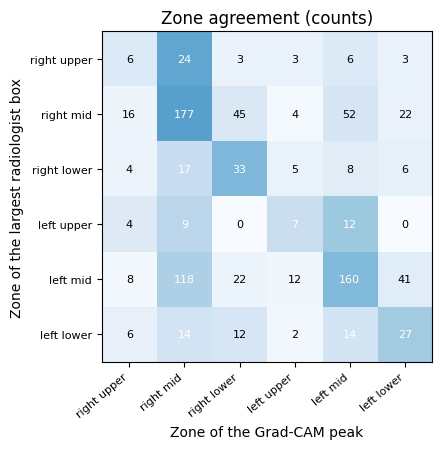

In [6]:
ZONES = ["right upper", "right mid", "right lower", "left upper", "left mid", "left lower"]
def zone_of(r, c):
    """Image-left is the patient's right. Rows 12%-88% of the image height are split into thirds (a heuristic, no lung mask)."""
    r, c = np.asarray(r, float), np.asarray(c, float)
    side = (c >= 128).astype(int)
    band = np.clip((r / 256 - 0.12) / 0.76, 0, 0.999)
    return side * 3 + (band * 3).astype(int)

gt_sets, gt_main = [], []
for p in pids:
    b = BOX[p]
    z = zone_of((b[:, 1] + b[:, 3] / 2) * S, (b[:, 0] + b[:, 2] / 2) * S)       # zone of each box centre
    gt_sets.append(set(z.tolist())); gt_main.append(int(z[np.argmax(b[:, 2] * b[:, 3])]))
gt_main = np.array(gt_main)

r_cam, c_cam = peak(cams)
cam_zone = zone_of(r_cam, c_cam)
pz = int(zone_of(pr_r, pr_c))
z_any = np.array([int(cz) in s for cz, s in zip(cam_zone, gt_sets)])
z_main = cam_zone == gt_main
print(f"CAM peak zone is one of the box zones : {z_any.mean():.3f}   (position-prior baseline {np.mean([pz in s for s in gt_sets]):.3f})")
print(f"CAM peak zone = zone of the largest box: {z_main.mean():.3f}   (position-prior baseline {np.mean(pz == gt_main):.3f})")

cm = np.zeros((6, 6), int)
for g_, c_ in zip(gt_main, cam_zone): cm[g_, c_] += 1
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.imshow(cm / cm.sum(1, keepdims=True).clip(1), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(6)); ax.set_xticklabels(ZONES, rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(6)); ax.set_yticklabels(ZONES, fontsize=8)
for i in range(6):
    for j in range(6): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.5 * cm[i].max() else "black")
ax.set_xlabel("Zone of the Grad-CAM peak"); ax.set_ylabel("Zone of the largest radiologist box"); ax.set_title("Zone agreement (counts)")
fig.tight_layout(); fig.savefig(OUT / "zone_confusion.png", dpi=150); plt.show()

In [7]:
# Sanity check: if the heatmaps really come from what the model learned, a randomly initialised model must do much worse.
rand_model = make_densenet().to(device).eval()
cams_rand = compute_cams(rand_model)
L_rand = localisation(cams_rand)
sc = pd.DataFrame({"trained model": {"pointing hit": L_cam["hit"].mean(), "IoU@0.5": L_cam["iou0.5"].mean()},
                   "random-weights model": {"pointing hit": L_rand["hit"].mean(), "IoU@0.5": L_rand["iou0.5"].mean()},
                   "position prior": {"pointing hit": L_prior["hit"].mean(), "IoU@0.5": L_prior["iou0.5"].mean()}})
print(sc.round(3))
del rand_model, cams_rand

              trained model  random-weights model  position prior
pointing hit          0.582                 0.041           0.594
IoU@0.5               0.300                 0.063           0.290


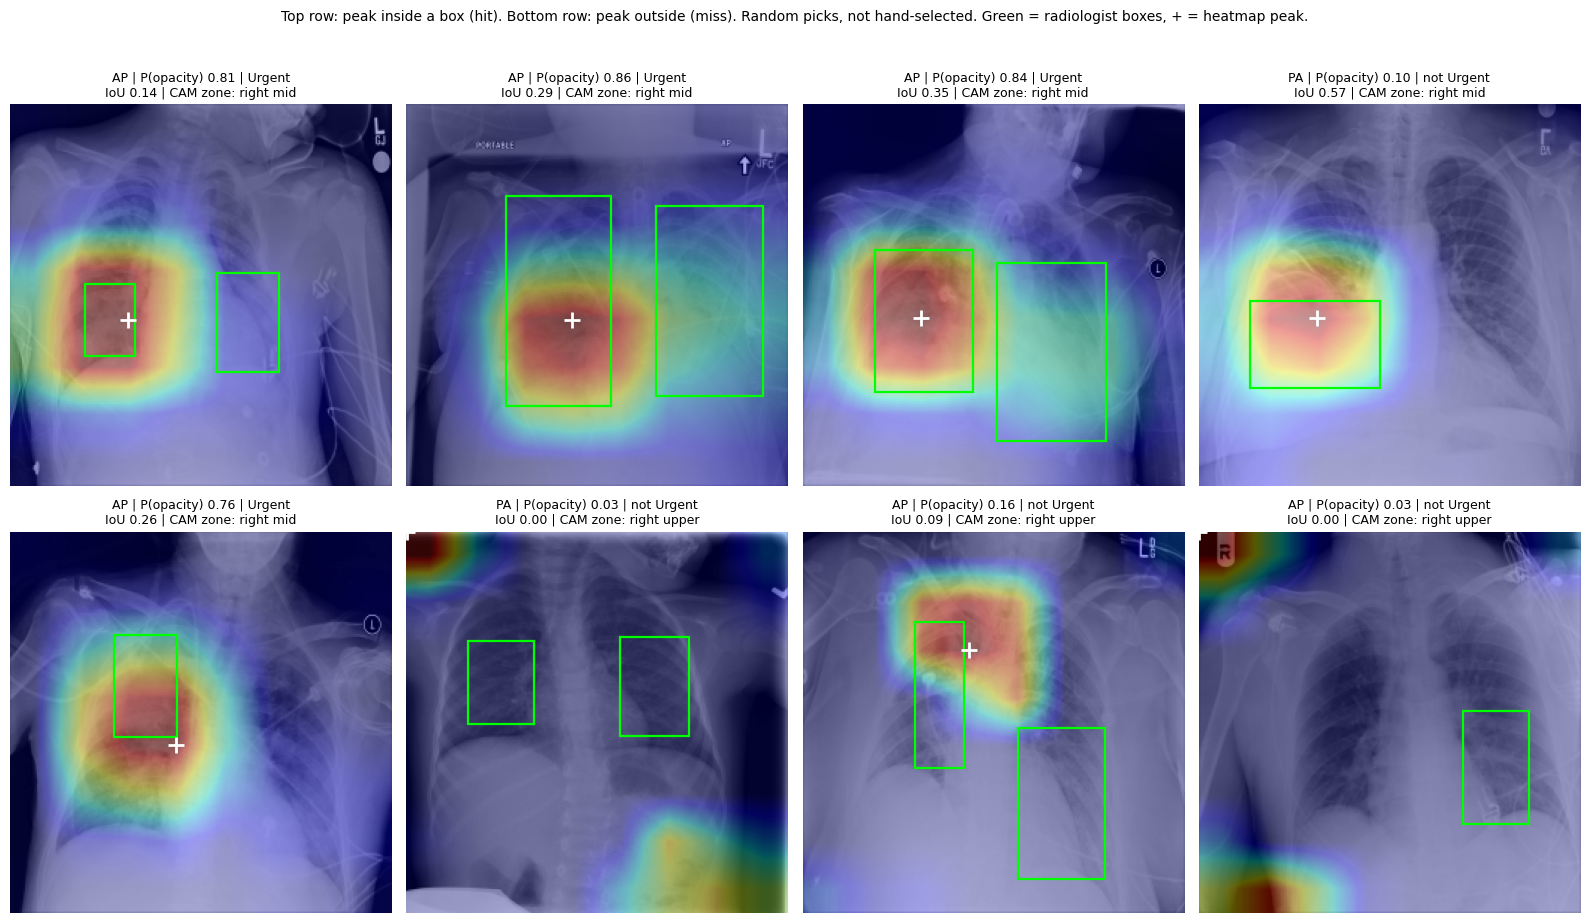

{
  "n_opacity_images": 902,
  "layer": "DenseNet121 final feature map (8x8, upsampled to 256x256)",
  "target_class": "Lung Opacity",
  "pointing_hit": [
    0.582039911308204,
    0.549889135254989,
    0.61529933481153
  ],
  "iou_0.5": [
    0.30002790109784755,
    0.28919048858531693,
    0.31117705738365825
  ],
  "energy_in_boxes": [
    0.29678713842092286,
    0.2849655026968387,
    0.30837193682101105
  ],
  "baseline_position_prior": {
    "pointing_hit": 0.5942350332594235,
    "iou_0.5": 0.2902847515952073
  },
  "baseline_random_point_hit": 0.12282525039300686,
  "random_weights_model": {
    "pointing_hit": 0.041019955654102,
    "iou_0.5": 0.06292432000542421
  },
  "zone_peak_in_box_zones": 0.6607538802660754,
  "zone_peak_equals_largest_box_zone": 0.45454545454545453,
  "note": "validation set only; ci = (mean, 2.5%, 97.5%) bootstrap"
}


In [8]:
rs = np.random.default_rng(42)
hit_idx, miss_idx = np.where(L_cam["hit"] == 1)[0], np.where(L_cam["hit"] == 0)[0]
pick = list(rs.choice(hit_idx, min(4, len(hit_idx)), replace=False)) + list(rs.choice(miss_idx, min(4, len(miss_idx)), replace=False))

fig, axes = plt.subplots(2, 4, figsize=(16, 9.6))
for ax, k in zip(axes.ravel(), pick):
    ax.imshow(IMGS[va["idx"].values[op_rows[k]]], cmap="gray")
    ax.imshow(cams[k], cmap="jet", alpha=0.35)
    for x0, y0, w, h in BOX[pids[k]]:
        ax.add_patch(plt.Rectangle((x0 * S, y0 * S), w * S, h * S, fill=False, ec="lime", lw=1.6))
    ax.plot(c_cam[k], r_cam[k], "w+", ms=11, mew=2)
    ax.set_title(f"{v_op[k]} | P(opacity) {P_op[k, 2]:.2f} | {'Urgent' if urgent[k] else 'not Urgent'}\n"
                 f"IoU {L_cam['iou0.5'][k]:.2f} | CAM zone: {ZONES[cam_zone[k]]}", fontsize=9)
    ax.axis("off")
fig.suptitle("Top row: peak inside a box (hit). Bottom row: peak outside (miss). Random picks, not hand-selected. Green = radiologist boxes, + = heatmap peak.", fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.95), h_pad=2.5); fig.savefig(OUT / "gradcam_examples.png", dpi=150); plt.show()

per_image = pd.DataFrame({"patientId": pids, "view": v_op, "p_opacity_calibrated": P_op[:, 2], "urgent": urgent,
                          "peak_row": r_cam, "peak_col": c_cam, "hit": L_cam["hit"], "energy": L_cam["energy"],
                          "iou_0.5": L_cam["iou0.5"], "cam_zone": [ZONES[z] for z in cam_zone], "largest_box_zone": [ZONES[z] for z in gt_main]})
per_image.to_csv(OUT / "gradcam_val_localization.csv", index=False)

summary = {"n_opacity_images": int(len(gt)), "layer": "DenseNet121 final feature map (8x8, upsampled to 256x256)", "target_class": "Lung Opacity",
           "pointing_hit": mean_ci(L_cam["hit"]), "iou_0.5": mean_ci(L_cam["iou0.5"]), "energy_in_boxes": mean_ci(L_cam["energy"]),
           "baseline_position_prior": {"pointing_hit": float(L_prior["hit"].mean()), "iou_0.5": float(L_prior["iou0.5"].mean())},
           "baseline_random_point_hit": chance_hit,
           "random_weights_model": {"pointing_hit": float(L_rand["hit"].mean()), "iou_0.5": float(L_rand["iou0.5"].mean())},
           "zone_peak_in_box_zones": float(z_any.mean()), "zone_peak_equals_largest_box_zone": float(z_main.mean()),
           "note": "validation set only; ci = (mean, 2.5%, 97.5%) bootstrap"}
json.dump(summary, open(OUT / "gradcam_metrics.json", "w"), indent=2)
print(json.dumps(summary, indent=2))